# Figure 2

In [26]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_choicehistoryeffect_contrasts,
    load_choicehistoryeffect_pairwise,
    load_rtlme_interaction_avgpred,
    load_rtlme_interaction_contrasts,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions
Refactored from `figures_draft_notebook/figure1_v2.ipynb` (psychometric curves) and `figures_draft_notebook/figure2_v3.ipynb` (RT LME emmeans).

In [27]:
def sig_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def add_significance_bracket(ax, x1, x2, y, h, p):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + h, sig_stars(p), ha="center", va="bottom")


def _lookup_contrast(contrasts_df, label_a, label_b):
    """avg_comparisons() contrast labels follow factor level order, not
    argument order, so try both "A - B" and "B - A"."""
    for label in (f"{label_a} - {label_b}", f"{label_b} - {label_a}"):
        match = contrasts_df[contrasts_df["contrast"] == label]
        if len(match):
            return match.iloc[0]
    raise KeyError(f"No contrast found for {label_a} vs {label_b}")


def get_condition_avgpred(avgpred_df, dataset, condition_label):
    row = avgpred_df[
        (avgpred_df["dataset"] == dataset) & (avgpred_df["condition"] == condition_label)
    ].iloc[0]
    return row["avgpred"], row["asymp.LCL"], row["asymp.UCL"]


def get_condition_contrast_pvalue(contrasts_df, dataset, label_a, label_b):
    ds_contrasts = contrasts_df[contrasts_df["dataset"] == dataset]
    return _lookup_contrast(ds_contrasts, label_a, label_b)["p.value"]

### 2x3 figure: choice-history effect by EV partition and RT estimated marginal means
Columns = datasets. Row 1: choice-history effect (Prev. Accept - Prev. Reject predicted P(accept)) by EV partition (low/medium/high), bars colored by BH-adjusted significance (2_choicehistoryeffect_contrasts.csv). Row 2: RT LME estimated marginal means (accept/reject x switch/repeat).

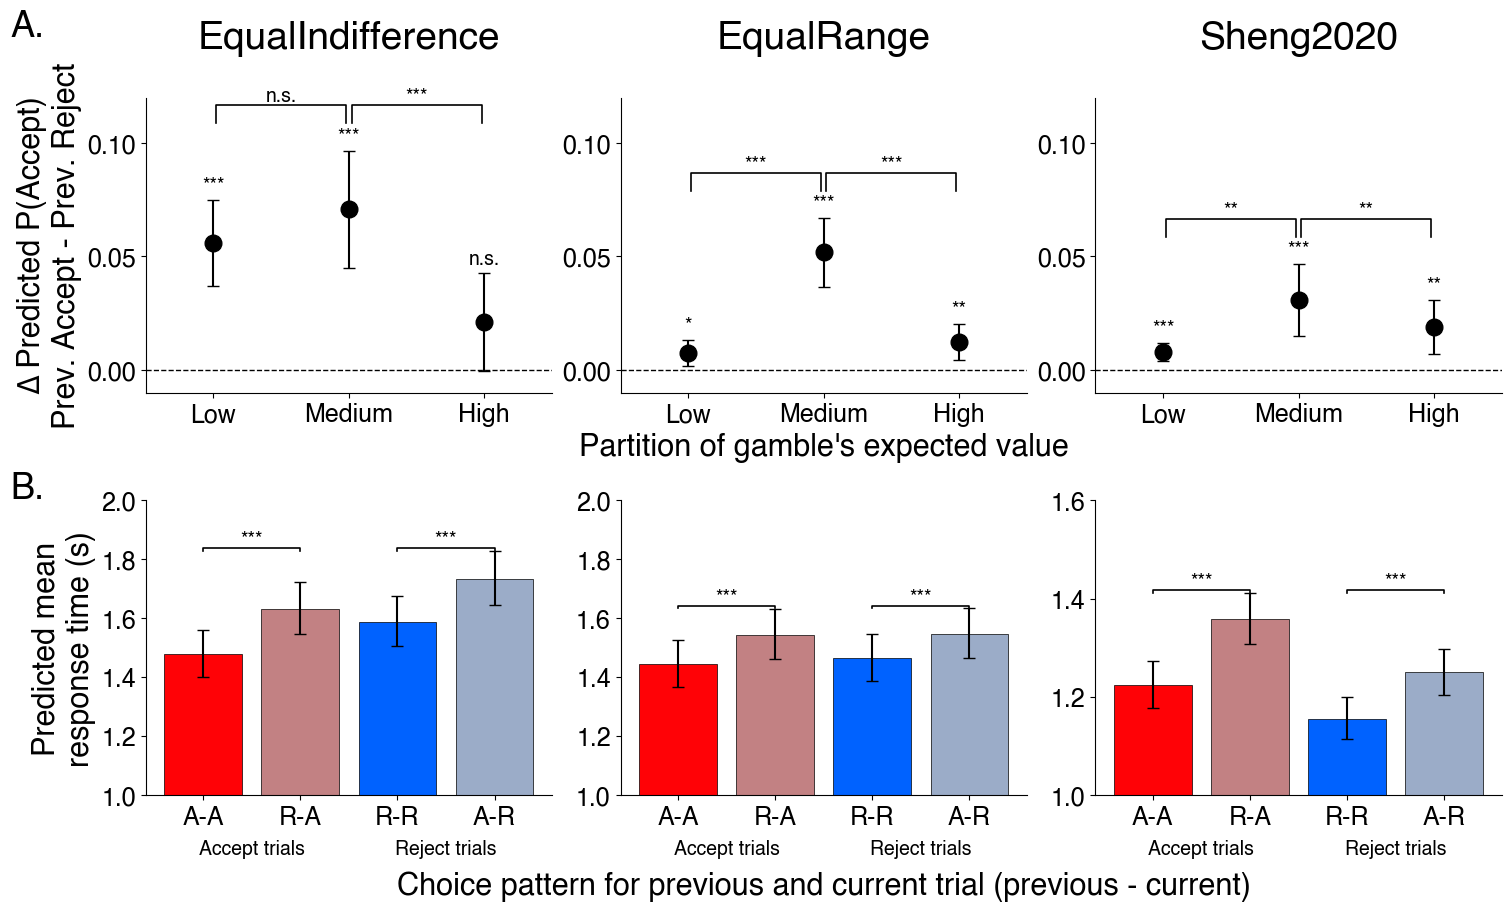

In [33]:
LINE_WIDTH = 4

# AA/RA/RR/AR = (previous choice, current choice): AA=accept_repeat,
# RA=accept_switch (prev reject, switched into accept), RR=reject_repeat,
# AR=reject_switch (prev accept, switched into reject). First two are
# Prev. Accept trials -> current accept; last two are current reject.
# Same color convention as figure4.ipynb's TRANSITION_COLORS.
BAR_ORDER = ["accept_repeat", "accept_switch", "reject_repeat", "reject_switch"]
BAR_COLORS = {
    "accept_repeat": "#FF0206",
    "accept_switch": "#C28183",
    "reject_repeat": "#0062FF",
    "reject_switch": "#9BACC8",
}

BAR_LABELS = {
    "accept_repeat": "A-A",
    "accept_switch": "R-A",
    "reject_repeat": "R-R",
    "reject_switch": "A-R",
}
# (x1, x2, label_a, label_b), shortest span last so the widest bracket stacks
# on top of the others.
BRACKET_PAIRS = [
    (0, 1, "accept_repeat", "accept_switch"),  # AA vs RA: within Prev. Accept
    (2, 3, "reject_repeat", "reject_switch"),  # RR vs AR: within Prev. Reject
]

# Row 1: choice-history effect (Prev. Accept - Prev. Reject predicted P(accept))
# by EV partition -- point estimate + 95% CI, with BH-adjusted significance
# stars above each point (reuses sig_stars() -- "n.s." when not significant).
# Fixed ylim across datasets so effect sizes are directly comparable.
EV_PARTITIONS = ["low", "medium", "high"]
EV_PARTITION_LABELS = {"low": "Low", "medium": "Medium", "high": "High"}
HISTORYEFFECT_COLOR = "black"
HISTORYEFFECT_YLIM = (-0.01, 0.12)

choicehistoryeffect_contrasts = load_choicehistoryeffect_contrasts()
choicehistoryeffect_pairwise = load_choicehistoryeffect_pairwise()

rtlme_interaction_avgpred = load_rtlme_interaction_avgpred()
rtlme_interaction_contrasts = load_rtlme_interaction_contrasts()

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 9), layout="constrained")

for col, ds in enumerate(DATASETS):
    # --- Row 1: choice-history effect by EV partition ---
    ax = axes[0, col]
    x_pos = np.arange(len(EV_PARTITIONS))
    ds_contrasts = (
        choicehistoryeffect_contrasts[choicehistoryeffect_contrasts["dataset"] == ds]
        .set_index("ev_partition").loc[EV_PARTITIONS]
    )
    ds_pairwise = choicehistoryeffect_pairwise[
        choicehistoryeffect_pairwise["dataset"] == ds
    ].set_index("contrast")

    means = ds_contrasts["historyeffect"].values
    los   = ds_contrasts["asymp.LCL"].values
    his   = ds_contrasts["asymp.UCL"].values
    yerr  = [means - los, his - means]

    ax.errorbar(x_pos, means, yerr=yerr, fmt="o", color=HISTORYEFFECT_COLOR,
               markersize=12, capsize=4, elinewidth=1.5, zorder=2)
    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=1)

    for x, y_top, p in zip(x_pos, his, ds_contrasts["p_adj_bh"]):
        ax.annotate(sig_stars(p), xy=(x, y_top), xytext=(0, 4),
                   textcoords="offset points", ha="center", va="bottom")

    bracket_y = his.max() + 0.012
    bracket_h = 0.008
    add_significance_bracket(ax, 0.02, 0.98, bracket_y, bracket_h,
                             ds_pairwise.loc["Medium - Low", "p_adj_bh"])
    add_significance_bracket(ax, 1.02, 1.98, bracket_y, bracket_h,
                             ds_pairwise.loc["High - Medium", "p_adj_bh"])

    ax.set_xlim(-0.5, len(EV_PARTITIONS) - 0.5)
    ax.set_ylim(*HISTORYEFFECT_YLIM)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([EV_PARTITION_LABELS[p] for p in EV_PARTITIONS])
    ax.set_title(f"{DATASET_LABELS.get(ds, ds)}\n")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if col == 0:
        ax.set_ylabel("∆ Predicted P(Accept)\nPrev. Accept - Prev. Reject")
    if col == 1:
        ax.set_xlabel("Partition of gamble's expected value")

    # --- Row 2: RT LME estimated marginal means ---
    ax_rt = axes[1, col]
    x_pos = np.arange(len(BAR_ORDER))
    vals = [get_condition_avgpred(rtlme_interaction_avgpred, ds, key) for key in BAR_ORDER]
    means = [v[0] for v in vals]
    los = [v[1] for v in vals]
    his = [v[2] for v in vals]
    yerr = [np.array(means) - np.array(los), np.array(his) - np.array(means)]
    colors = [BAR_COLORS[key] for key in BAR_ORDER]

    ax_rt.bar(x_pos, means, yerr=yerr, color=colors, capsize=4,
             edgecolor="black", linewidth=0.5, zorder=2)

    y_bracket = max(his)
    bracket_h = 0.005 * y_bracket
    n_tiers = len(BRACKET_PAIRS)
    for tier, (x1, x2, label_a, label_b) in enumerate(BRACKET_PAIRS):
        p_val = get_condition_contrast_pvalue(rtlme_interaction_contrasts, ds, label_a, label_b)
        add_significance_bracket(ax_rt, x1, x2, y_bracket, bracket_h, p_val)

    ylim_top = 2
    if ds == "sheng2020":
        ylim_top = 1.6
    ax_rt.set_ylim(1, ylim_top)

    ax_rt.set_xticks(x_pos)
    ax_rt.set_xticklabels([BAR_LABELS[key] for key in BAR_ORDER])
    ax_rt.spines["top"].set_visible(False)
    ax_rt.spines["right"].set_visible(False)

    # Group labels below the x-axis: first two bars = Prev. Accept trials,
    # last two = Prev. Reject trials (x in data coords, y in axes fraction).
    ax_rt.text(0.5, -0.15, "Accept trials", transform=ax_rt.get_xaxis_transform(),
              ha="center", va="top")
    ax_rt.text(2.5, -0.15, "Reject trials", transform=ax_rt.get_xaxis_transform(),
              ha="center", va="top")

    if col == 0:
        ax_rt.set_ylabel("Predicted mean\nresponse time (s)")
    if col == 1:
        ax_rt.set_xlabel("Choice pattern for previous and current trial (previous - current)", labelpad=30)

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.25, 1.3, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.25, 1.1, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
fig.savefig("saved/figure2.svg", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
choicehistoryeffect_contrasts

,dataset,ev_partition,historyeffect,SE,z.ratio,asymp.LCL,asymp.UCL,p.value,p_adj_bh
0,sheng2020,low,0.007941,0.001971,4.028545,0.004078,0.011805,5.612309e-05,1.683693e-04
1,sheng2020,medium,0.030710,0.008067,3.806717,0.014898,0.046521,1.408236e-04,2.112354e-04
2,sheng2020,high,0.019058,0.006076,3.136447,0.007149,0.030967,1.710081e-03,1.710081e-03
3,equalRange,low,0.007531,0.002973,2.533214,0.001704,0.013358,1.130218e-02,1.130218e-02
4,equalRange,medium,0.051751,0.007675,6.742899,0.036709,0.066794,1.552577e-11,4.657730e-11
5,equalRange,high,0.012279,0.003987,3.079593,0.004464,0.020094,2.072839e-03,3.109258e-03
6,equalIndifference,low,0.055910,0.009694,5.767736,0.036911,0.074910,8.034367e-09,2.410310e-08
7,equalIndifference,medium,0.070853,0.013175,5.377773,0.045030,0.096676,7.541263e-08,1.131189e-07
8,equalIndifference,high,0.020935,0.011036,1.897038,-0.000694,0.042565,5.782293e-02,5.782293e-02


In [5]:
rtlme_interaction_contrasts

,dataset,contrast,estimate,p.value,p_adj_bh
0,equalIndifference,accept_switch - accept_repeat,1.073900,3.320654e-27,6.641308e-27
1,equalIndifference,reject_switch - reject_repeat,1.054687,9.459890e-11,9.459890e-11
2,equalRange,accept_switch - accept_repeat,1.062493,5.535070e-18,1.107014e-17
3,equalRange,reject_switch - reject_repeat,1.028924,1.310581e-05,1.310581e-05
4,sheng2020,accept_switch - accept_repeat,1.079064,1.934129e-19,1.934129e-19
5,sheng2020,reject_switch - reject_repeat,1.059746,3.433278e-20,6.866557e-20


In [6]:
rtlme_interaction_avgpred

,dataset,condition,avgpred,asymp.LCL,asymp.UCL,p.value
0,equalIndifference,reject_repeat,1.519213,1.439137,1.603744,9.246486e-52
1,equalIndifference,reject_switch,1.702445,1.614419,1.795270,6.687207e-86
2,equalIndifference,accept_repeat,1.490822,1.413287,1.572610,1.267147e-48
3,equalIndifference,accept_switch,1.619126,1.534312,1.708629,5.555389e-69
4,equalRange,reject_repeat,1.470258,1.391206,1.553802,1.555306e-42
5,equalRange,reject_switch,1.533335,1.451125,1.620203,3.379314e-52
6,equalRange,accept_repeat,1.439476,1.362499,1.520801,1.374079e-38
7,equalRange,accept_switch,1.537160,1.455215,1.623720,2.169632e-53
8,sheng2020,reject_repeat,1.133036,1.092094,1.175512,2.898771e-11
9,sheng2020,reject_switch,1.227659,1.182612,1.274422,5.700246e-27
